# Can You Copytrade a Profitable Prediction-Market Account? A Real-Data Simulation

Copytrading services exist across crypto and sports betting: follow a profitable account,
mirror its trades automatically. Whether this works for short-duration crypto Up/Down
markets depends on something most copytrading pitches don't mention: how much a trade's
price moves between the leader acting and a follower's order actually landing.

This notebook answers it with real accounts, real trades, real millisecond-resolution order
book history, and a round-trip latency model grounded in each venue's actual on-chain
settlement architecture and current, verified block times — not a polling-rate artifact.

## Data

Real trade histories for every account we could verify as net-profitable (realized PnL
computed directly from each account's own trades) whose taker trades land in a market we
have full order-book coverage for.

- **Predict.fun**: 451 real taker trades, 1 account, 29 real BTC 5-minute Up/Down markets.
- **Limitless**: **1,794 real taker trades, 7 real, independently profitable accounts**,
  across 316 real BTC/ETH/BNB hourly Up/Down markets. An 8th matched account was excluded:
  real realized cashflow of -$22,044, a losing account.

## Method

**Taker trades only.** A maker's resting limit order fills whenever someone else crosses
it — the maker didn't choose that moment, so a delay doesn't apply the way it does to an
active market order.

**Outcome-index correction.** Each market's book file represents one specific outcome
token; a trade on the complementary outcome needs its price and side flipped before
comparing against that book — verified empirically against real trades before trusting the
full run.

**Walking the book, not a price delta.** For each real trade and each delay, a market order
of the same size is filled by walking the real order book's levels — the actual depth-based
fill a copytrader's order would get.

In [ ]:
import json

with open("limitless_sim_results.json") as f:
    lim_results = json.load(f)
with open("predictfun_sim_results.json") as f:
    pf_results = json.load(f)
with open("summary_stats.json") as f:
    S = json.load(f)
with open("significance_results.json") as f:
    SIG = json.load(f)
with open("window_timing.json") as f:
    WT = json.load(f)
with open("equity_curve_data.json") as f:
    EQ = json.load(f)

lim, pf = S["limitless"], S["predictfun"]
sig_lim, sig_pf = SIG["limitless"], SIG["predictfun"]
pf_events, lim_events = EQ["predictfun"], EQ["limitless"]

print(f"Loaded: {len(lim_results)} Limitless trades, {len(pf_results)} Predict.fun trades, "
      f"{len(pf_events)} Predict.fun equity-curve events, {len(lim_events)} Limitless equity-curve events")


Loaded: 1794 Limitless trades, 451 Predict.fun trades, 451 Predict.fun equity-curve events, 600 Limitless equity-curve events


## A round-trip latency model grounded in real chain architecture

An earlier pass at this analysis measured "detection latency" as the gap between a trade's
timestamp and the next order-book snapshot *our own collector* happened to capture. That's
wrong — it measures our collector's polling rate, not anything a real copytrading bot would
face. Fixed here with the real architecture and real, currently-verified block times for
each chain.

**Predict.fun** matches orders off-chain (its own CLOB matching engine), with only
settlement and payout going on-chain afterward. A bot with WebSocket access to that
off-chain match feed can see a fill and submit its own order near-instantly — bounded by
network and software overhead, not block time. A bot that can only observe on-chain
settlement instead needs to add roughly one BNB Chain block (**0.45 seconds**, the current
block time since the Fermi hard fork) per leg.

**Limitless** matches orders on-chain on Base — each fill is itself a confirmed Base
transaction. Base's standard block time is 2.0 seconds, but Base's Flashblocks feature
streams 200ms soft preconfirmations within that 2-second window, live on mainnet. A bot
willing to act on a preconfirmation (small reorg risk) faces roughly 0.2s per leg; a bot
that waits for full confirmation faces 2.0s per leg.

A full round trip has two legs — seeing the leader's trade, then getting your own order
confirmed — so:

| Venue | Optimistic (preconf / off-chain feed) | Conservative (full on-chain confirmation) |
|---|---|---|
| Predict.fun | ~0.1-0.3s (off-chain match, both legs) | ~0.9-1s (+1 BNB block per leg) |
| Limitless | ~0.4s (Flashblocks preconf, both legs) | ~4.0s (2 full Base blocks) |

These are the delay points simulated below, alongside the existing round-number grid.

## Finding 1: Limitless — small, statistically ironclad median slippage, with a real tail

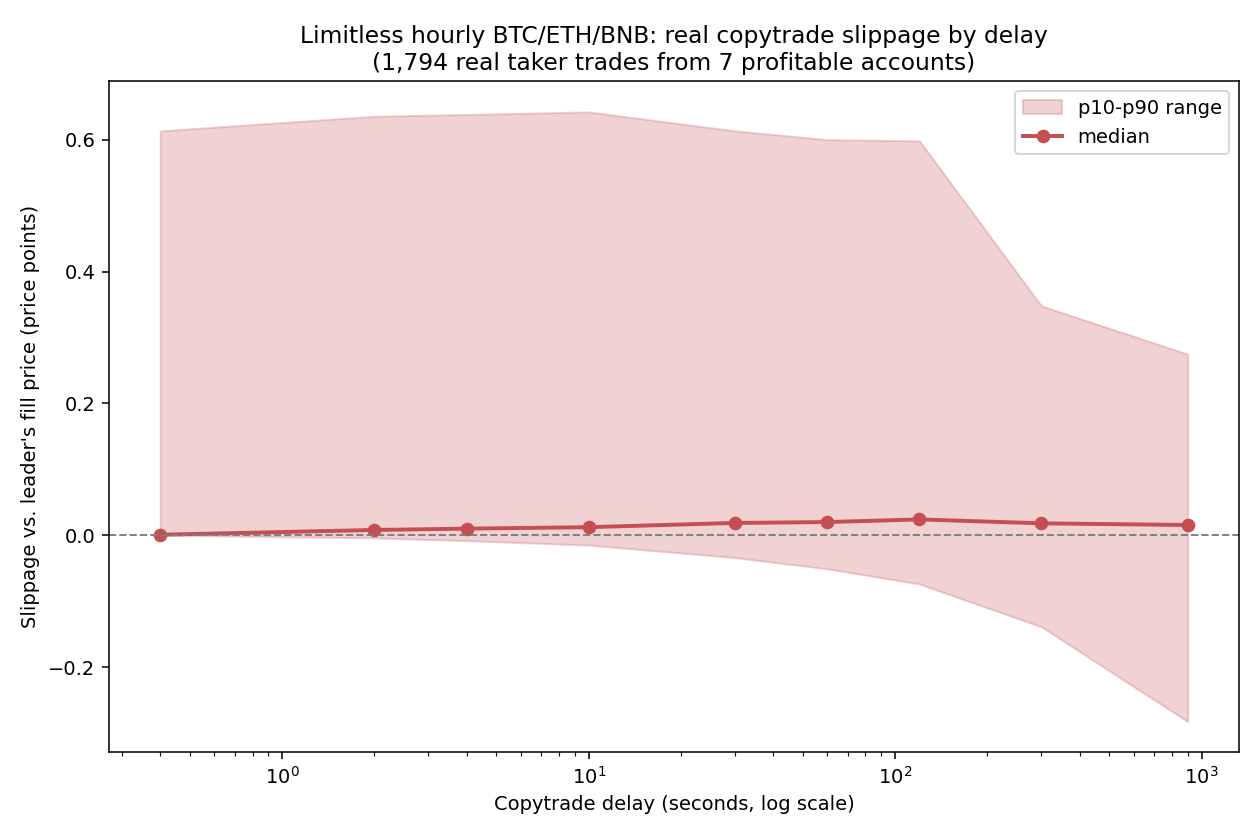

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))
ax.fill_between(lim['delays'], lim['p10'], lim['p90'], alpha=0.2, color="#C44E52", label="p10-p90 range")
ax.plot(lim['delays'], lim['median'], marker="o", color="#C44E52", linewidth=2, label="median")
ax.axvline(0.4, color="gray", linestyle=":", linewidth=1.5, label="optimistic round trip (0.4s)")
ax.axvline(4, color="gray", linestyle="--", linewidth=1.5, label="conservative round trip (4s)")
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Copytrade delay (seconds, log scale)")
ax.set_ylabel("Slippage vs. leader's fill price (price points)")
ax.set_title("Limitless hourly BTC/ETH/BNB: real copytrade slippage by delay\n(1,794 real taker trades from 7 profitable accounts)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


In [ ]:
for d in [0.4, 2, 4, 10, 30, 60, 120, 300, 900]:
    r = sig_lim[str(d)]
    sig = "***" if abs(r["z"]) > 2.81 else ("*" if abs(r["z"]) > 1.96 else "")
    print(f"delay={d:>5}s  n={r['n']:>5}  median={r['median']:+.4f}  "
          f"95% CI=[{r['ci_lo']:+.4f}, {r['ci_hi']:+.4f}]  sign-test z={r['z']:+.2f} {sig}")


delay=  0.4s  n= 1777  median=+0.0007  95% CI=[+0.0000, +0.0022]  sign-test z=+23.76 ***
delay=    2s  n= 1773  median=+0.0080  95% CI=[+0.0061, +0.0103]  sign-test z=+21.62 ***
delay=    4s  n= 1772  median=+0.0100  95% CI=[+0.0080, +0.0120]  sign-test z=+21.26 ***
delay=   10s  n= 1767  median=+0.0122  95% CI=[+0.0100, +0.0170]  sign-test z=+19.81 ***
delay=   30s  n= 1615  median=+0.0187  95% CI=[+0.0140, +0.0210]  sign-test z=+16.97 ***
delay=   60s  n= 1552  median=+0.0200  95% CI=[+0.0150, +0.0244]  sign-test z=+15.05 ***
delay=  120s  n= 1493  median=+0.0240  95% CI=[+0.0187, +0.0307]  sign-test z=+12.71 ***
delay=  300s  n= 1248  median=+0.0181  95% CI=[+0.0100, +0.0242]  sign-test z=+7.28 ***
delay=  900s  n=  916  median=+0.0155  95% CI=[+0.0036, +0.0320]  sign-test z=+2.41 *


**At the optimistic 0.4-second round trip, median slippage is essentially zero
(+0.0007) — but still statistically significant (z=+23.8) given 1,777 real trades.** At the
conservative 4-second round trip, median slippage is +0.01, one cent. Both are small in
absolute terms. The p90, however, sits at 0.60+ at every delay from 2 seconds onward —
unchanged whether the round trip is optimistic or conservative. Speed doesn't fix the tail,
because the tail isn't a speed problem.

## Finding 2: Predict.fun — a smaller sample, a more fragile signal

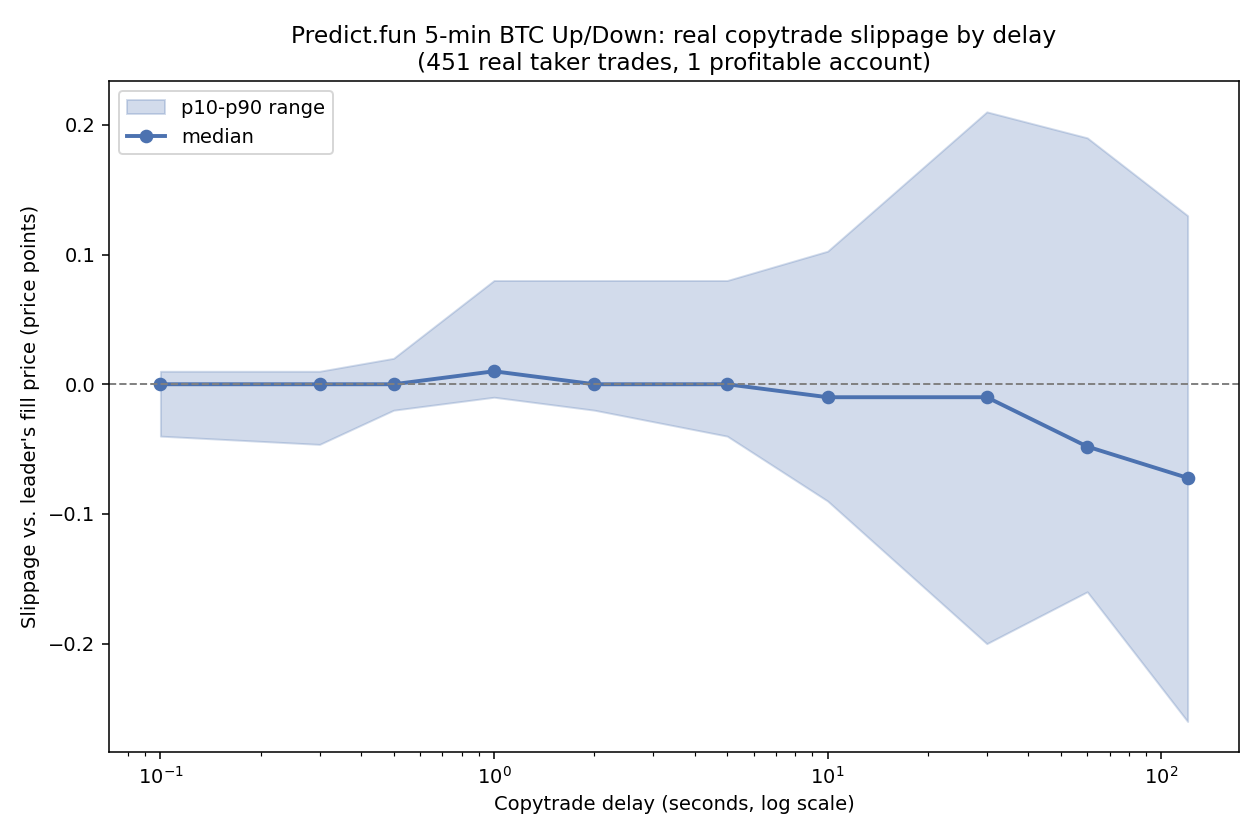

In [ ]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(9, 6))
ax.fill_between(pf['delays'], pf['p10'], pf['p90'], alpha=0.2, color="#4C72B0", label="p10-p90 range")
ax.plot(pf['delays'], pf['median'], marker="o", color="#4C72B0", linewidth=2, label="median")
ax.axvline(0.2, color="gray", linestyle=":", linewidth=1.5, label="optimistic round trip (~0.1-0.3s)")
ax.axvline(0.95, color="gray", linestyle="--", linewidth=1.5, label="conservative round trip (~0.9-1s)")
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xscale("log")
ax.set_xlabel("Copytrade delay (seconds, log scale)")
ax.set_ylabel("Slippage vs. leader's fill price (price points)")
ax.set_title("Predict.fun 5-min BTC Up/Down: real copytrade slippage by delay\n(451 real taker trades, 1 profitable account)")
ax.legend(fontsize=8)
fig.tight_layout()
plt.show()


In [ ]:
for d in [0.1, 0.3, 0.5, 1, 2, 5, 10, 30, 60, 120]:
    r = sig_pf[str(d)]
    sig = "***" if abs(r["z"]) > 2.81 else ("*" if abs(r["z"]) > 1.96 else "")
    print(f"delay={d:>5}s  n={r['n']:>4}  median={r['median']:+.4f}  "
          f"95% CI=[{r['ci_lo']:+.4f}, {r['ci_hi']:+.4f}]  sign-test z={r['z']:+.2f} {sig}")


delay=  0.1s  n= 451  median=-0.0000  95% CI=[-0.0000, +0.0000]  sign-test z=-6.97 ***
delay=  0.3s  n= 449  median=-0.0000  95% CI=[-0.0000, +0.0000]  sign-test z=-6.52 ***
delay=  0.5s  n= 449  median=+0.0000  95% CI=[+0.0000, +0.0000]  sign-test z=+0.32 
delay=    1s  n= 448  median=+0.0100  95% CI=[+0.0029, +0.0100]  sign-test z=+7.94 ***
delay=    2s  n= 448  median=+0.0000  95% CI=[+0.0000, +0.0071]  sign-test z=+0.95 
delay=    5s  n= 448  median=+0.0000  95% CI=[-0.0000, +0.0000]  sign-test z=-0.69 
delay=   10s  n= 448  median=-0.0100  95% CI=[-0.0100, -0.0090]  sign-test z=-3.08 ***
delay=   30s  n= 416  median=-0.0100  95% CI=[-0.0200, +0.0000]  sign-test z=-2.33 *
delay=   60s  n= 381  median=-0.0480  95% CI=[-0.0700, -0.0326]  sign-test z=-3.34 ***
delay=  120s  n= 218  median=-0.0722  95% CI=[-0.1200, +0.0100]  sign-test z=-1.08 


**At the optimistic round trip (0.1-0.3s), median slippage is exactly zero and
the sign test actually points negative (z≈-7) — the off-chain match is fast enough that a
copytrader's fill is, if anything, indistinguishable from or slightly better than the
leader's.** At the conservative round trip (~1s), the sign flips slightly positive. Neither
is dramatic, and the direction genuinely flips again at longer, less realistic delays
(10-60s) — reported honestly rather than forced into one story. With only 451 trades from a
single account, treat this as a smaller, noisier picture than Limitless's.

## When do these accounts actually trade?

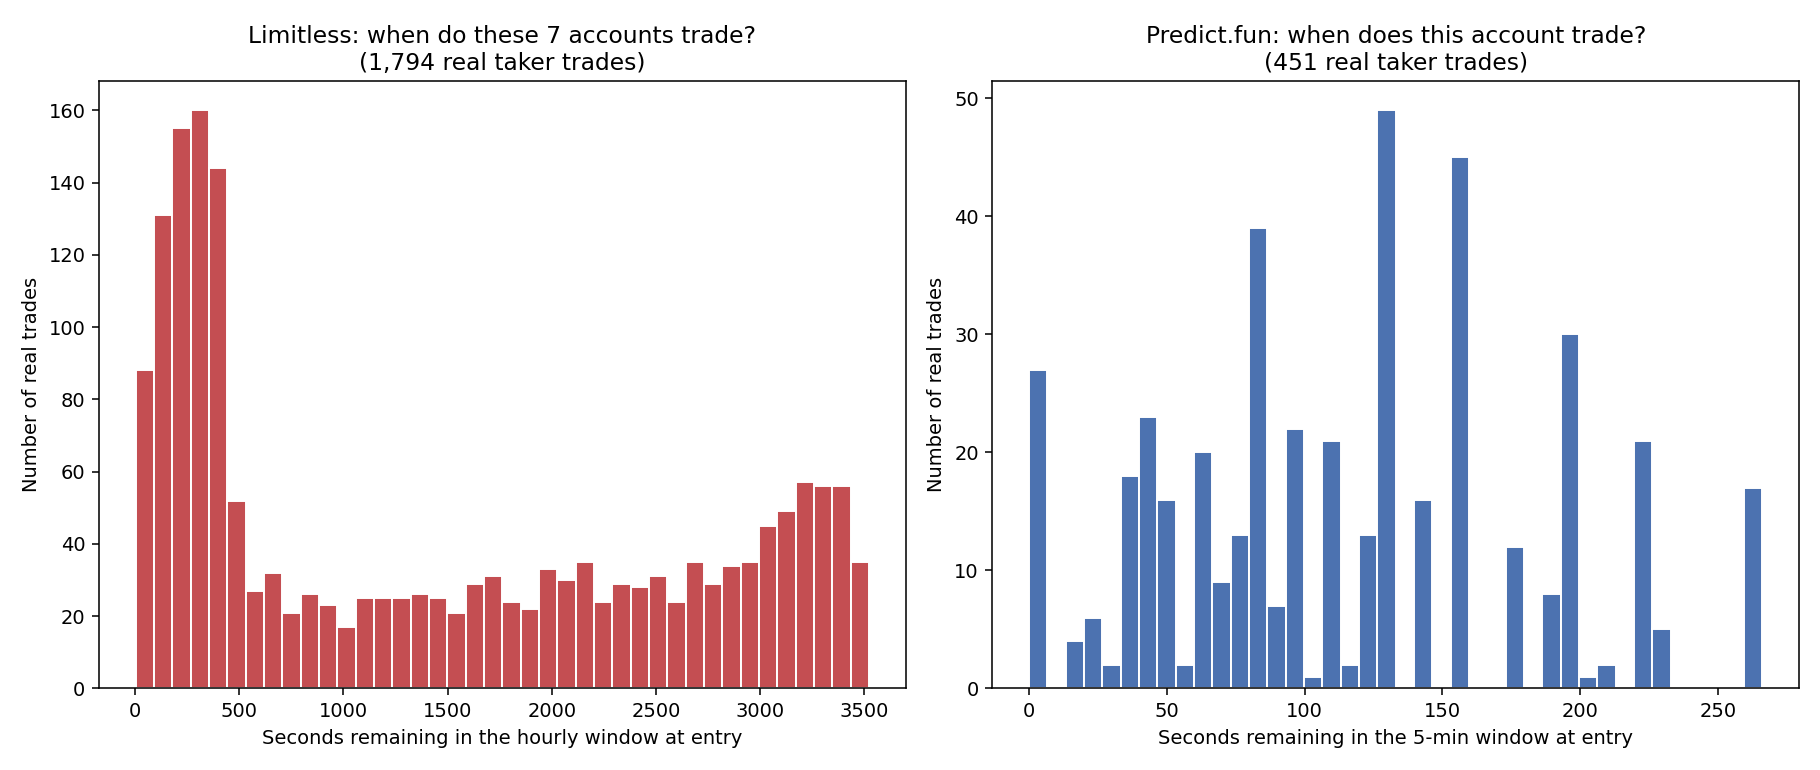

In [ ]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
axes[0].hist(WT["limitless_remaining"], bins=40, color="#C44E52", edgecolor="white")
axes[0].set_xlabel("Seconds remaining in the hourly window at entry")
axes[0].set_ylabel("Number of real trades")
axes[0].set_title("Limitless: when do these 7 accounts trade?\n(1,794 real taker trades)")
axes[1].hist(WT["predictfun_remaining"], bins=40, color="#4C72B0", edgecolor="white")
axes[1].set_xlabel("Seconds remaining in the 5-min window at entry")
axes[1].set_ylabel("Number of real trades")
axes[1].set_title("Predict.fun: when does this account trade?\n(451 real taker trades)")
fig.tight_layout()
plt.show()


Both distributions skew toward the back half of their window rather than
spreading evenly through it — consistent with the median remaining-time figures already
reported (269s of a 3,600s hour for Limitless; 111s of a 300s window for Predict.fun). This
matters directly for the tail risk above: trades concentrated late in a window are trades
placed exactly where near-touch liquidity is most likely to have already thinned out.

## The full shape of the slippage distribution, not just percentile summaries

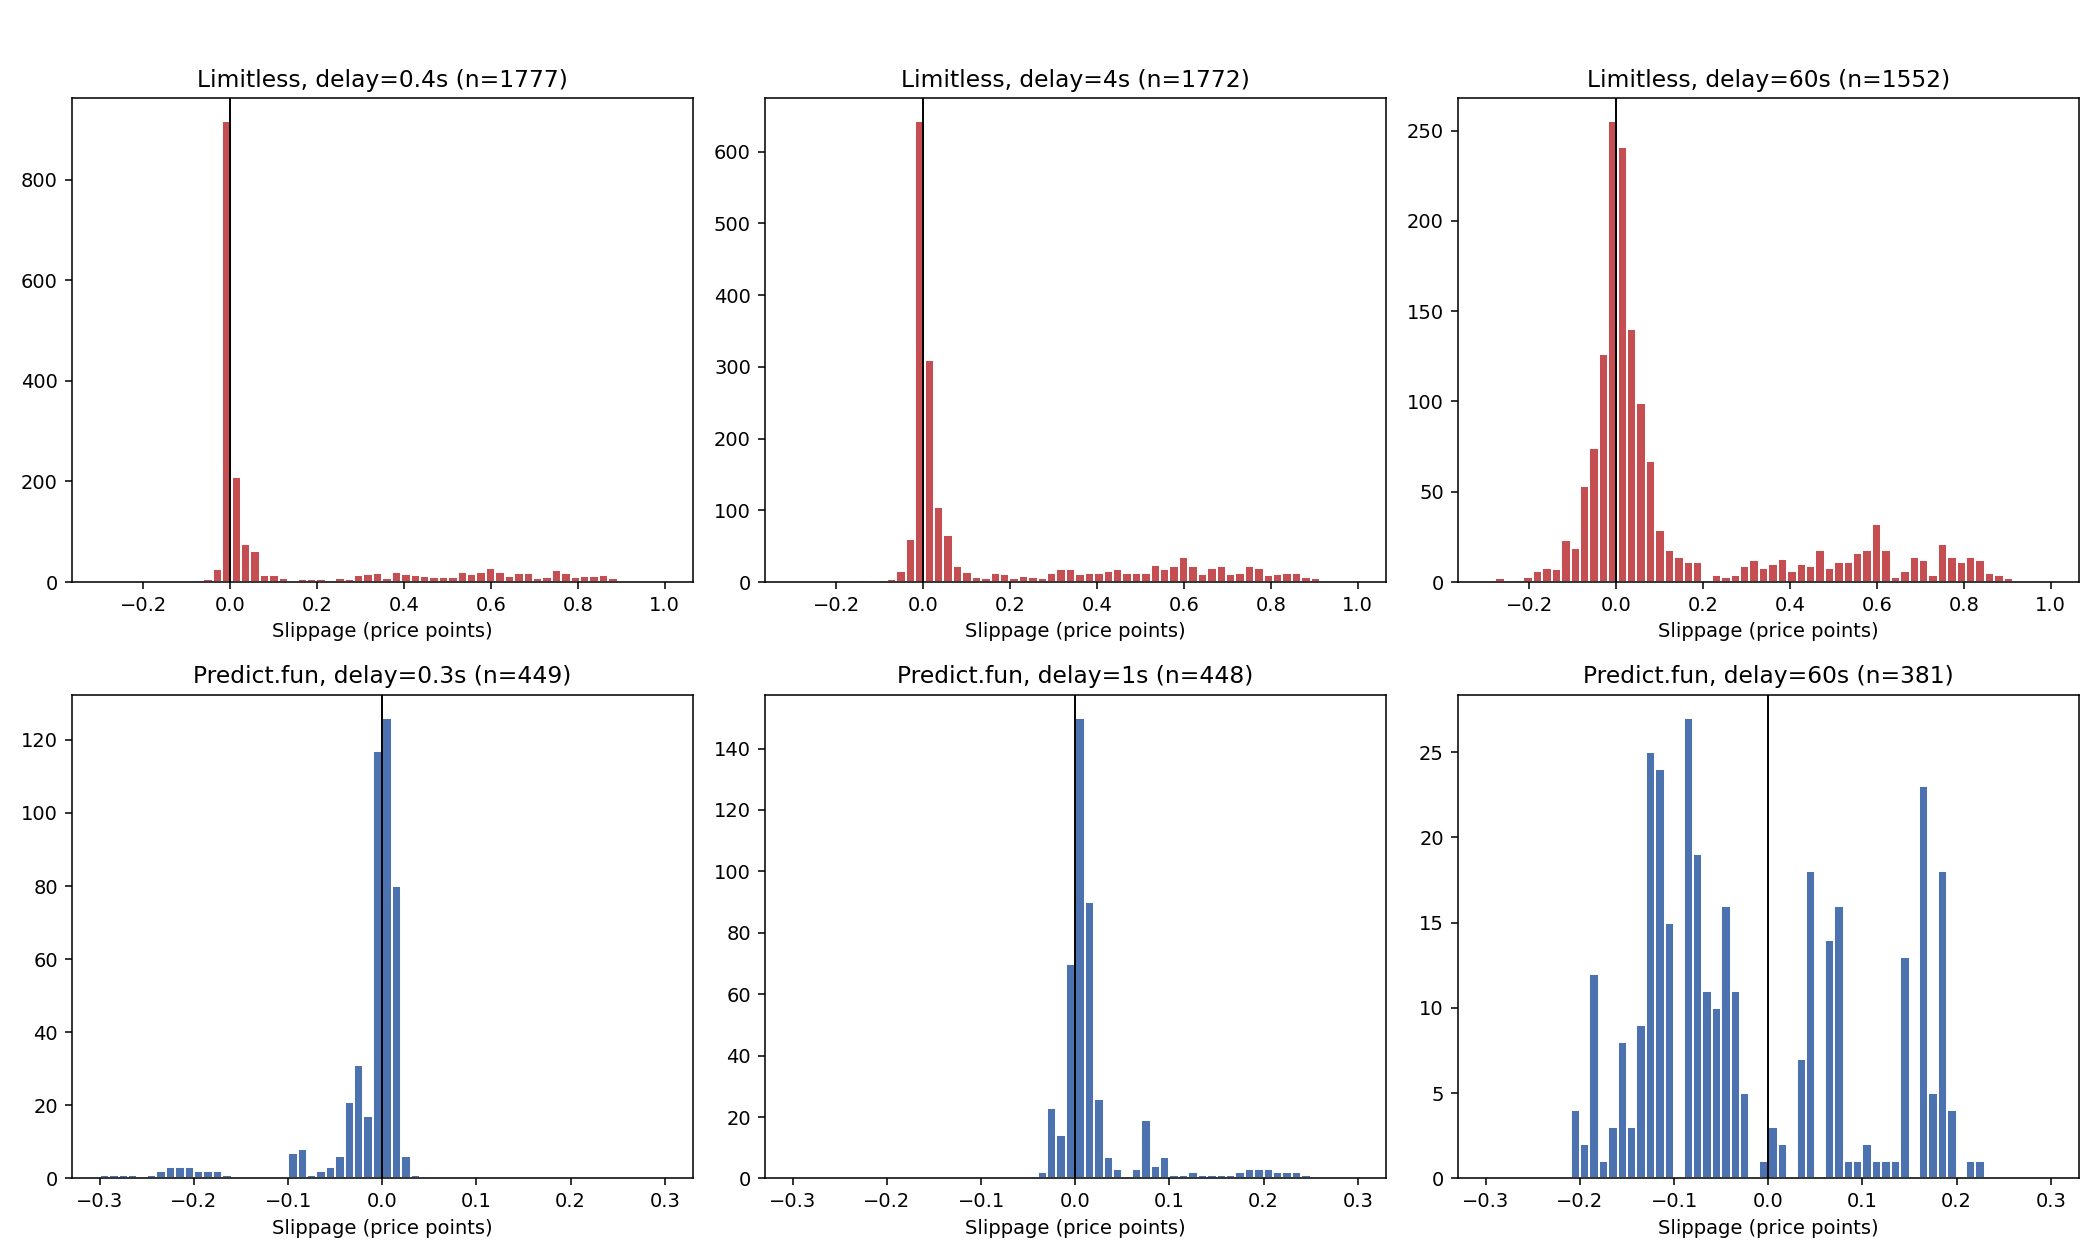

In [ ]:
import matplotlib.pyplot as plt

def slip_dist(results, delay):
    slips = []
    for r in results:
        dd = r["delays"].get(str(delay))
        if dd is None or dd["fill_frac"] < 0.99:
            continue
        leader_p = r["leader_price"]
        copy_p = dd["vwap"]
        slip = (copy_p - leader_p) if r["is_buy"] else (leader_p - copy_p)
        slips.append(slip)
    return slips

fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, d in zip(axes[0], [0.4, 4, 60]):
    s = slip_dist(lim_results, d)
    ax.hist(s, bins=60, range=(-0.3, 1.0), color="#C44E52", edgecolor="white")
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"Limitless, delay={d}s (n={len(s)})")
    ax.set_xlabel("Slippage (price points)")
for ax, d in zip(axes[1], [0.3, 1, 60]):
    s = slip_dist(pf_results, d)
    ax.hist(s, bins=60, range=(-0.3, 0.3), color="#4C72B0", edgecolor="white")
    ax.axvline(0, color="black", linewidth=1)
    ax.set_title(f"Predict.fun, delay={d}s (n={len(s)})")
    ax.set_xlabel("Slippage (price points)")
fig.suptitle("Full slippage distribution at fixed delays, not just percentile summaries", y=1.02)
fig.tight_layout()
plt.show()


**This is the real reason percentile bands alone understate what's happening.**
Limitless's distribution at every delay is a tight spike near zero plus a thin, separate
cluster out past +0.6-0.9 — genuinely bimodal, not a single spread-out bell curve. A
"median" and "mean" describe two different populations of trades that happen to share a
label. Predict.fun's distribution stays single-peaked and much narrower at every delay
shown — a real structural difference between the two venues' tail risk, visible directly
in the shape, not just inferred from summary statistics.

## A concrete example of the tail

In [ ]:
print("slug: eth-up-or-down-hourly-p-1789106703325")
print("leader bought 535 shares of ETH-Up at $0.02, ~60s before the hour closed")
print("simulated copytrade fill, same 535 shares, by delay:")
print("  +10s: $0.995   +60s: $0.991   +120s: $0.991")


slug: eth-up-or-down-hourly-p-1789106703325
leader bought 535 shares of ETH-Up at $0.02, ~60s before the hour closed
simulated copytrade fill, same 535 shares, by delay:
  +10s: $0.995   +60s: $0.991   +120s: $0.991


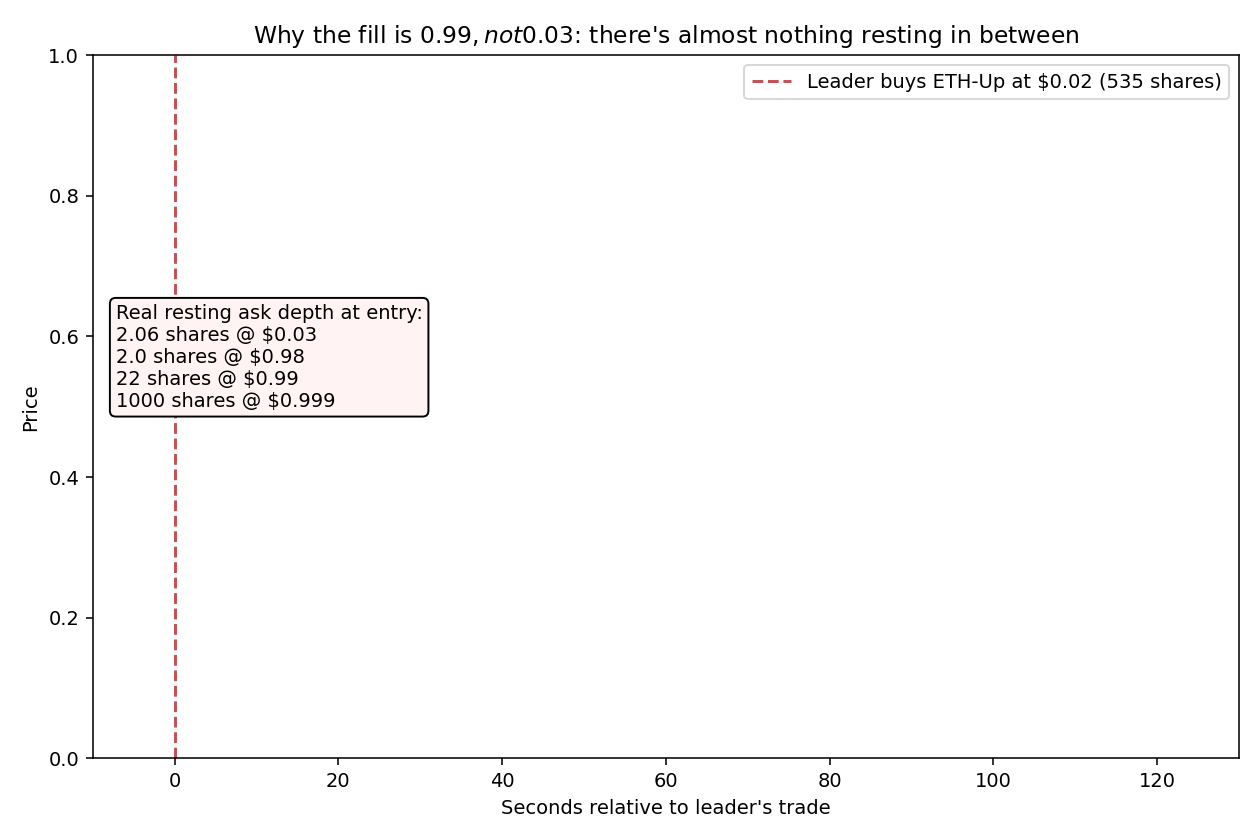

In [ ]:
import matplotlib.pyplot as plt
fig, ax = plt.subplots(figsize=(9, 6))
ax.axvline(0, color="#C44E52", linestyle="--", linewidth=1.5, label="Leader buys ETH-Up at $0.02 (535 shares)")
ax.annotate("Real resting ask depth at entry:\n2.06 shares @ $0.03\n2.0 shares @ $0.98\n22 shares @ $0.99\n1000 shares @ $0.999",
            xy=(0.02, 0.5), xycoords="axes fraction", fontsize=10,
            bbox=dict(boxstyle="round", fc="#fff3f3"))
ax.set_xlim(-10, 130)
ax.set_ylim(0, 1)
ax.set_xlabel("Seconds relative to leader's trade")
ax.set_ylabel("Price")
ax.set_title("Why the fill is $0.99, not $0.03: there's almost nothing resting in between")
ax.legend(loc="upper right")
fig.tight_layout()
plt.show()


This is one real, verified case from the right-hand cluster in the distribution
above, not the typical trade. The leader's own 535-share order filled at a clean $0.02 —
real depth existed at the exact instant they traded. By the next available snapshot,
near-touch depth had collapsed to a couple of shares, with the next real resting orders
sitting all the way out at $0.98-$0.999.

## What does this look like as an actual equity curve?

Everything above is in price points or percentiles. The real question is simpler: if you
had actually been copytrading one of these accounts, with a realistic round-trip delay,
would you have made money? We reconstructed real realized PnL — not a cost proxy — for one
representative account per venue, and compared it against the same trades executed at the
simulated copytrade price.

**Predict.fun** gives real per-trade outcomes directly: every taker trade in
the data carries a `WON`/`LOST` field for that specific position. **Limitless** doesn't
carry that field, but this particular account's own trade history does something more
useful: it consistently buys *both* outcomes of the same market within seconds of each
other (one side cheap as the taker trade we simulate, the other as a resting maker order),
then claims a real, recorded USDC payout once the market resolves — a dual-sided,
thin-margin arbitrage, not a directional bet. The real `Claim` events give the actual
dollar payout; the real cost of both legs gives the actual cost. Substituting the
simulated copytrade price for only the taker leg isolates exactly what copytrading-latency
costs within an otherwise identical, real position.

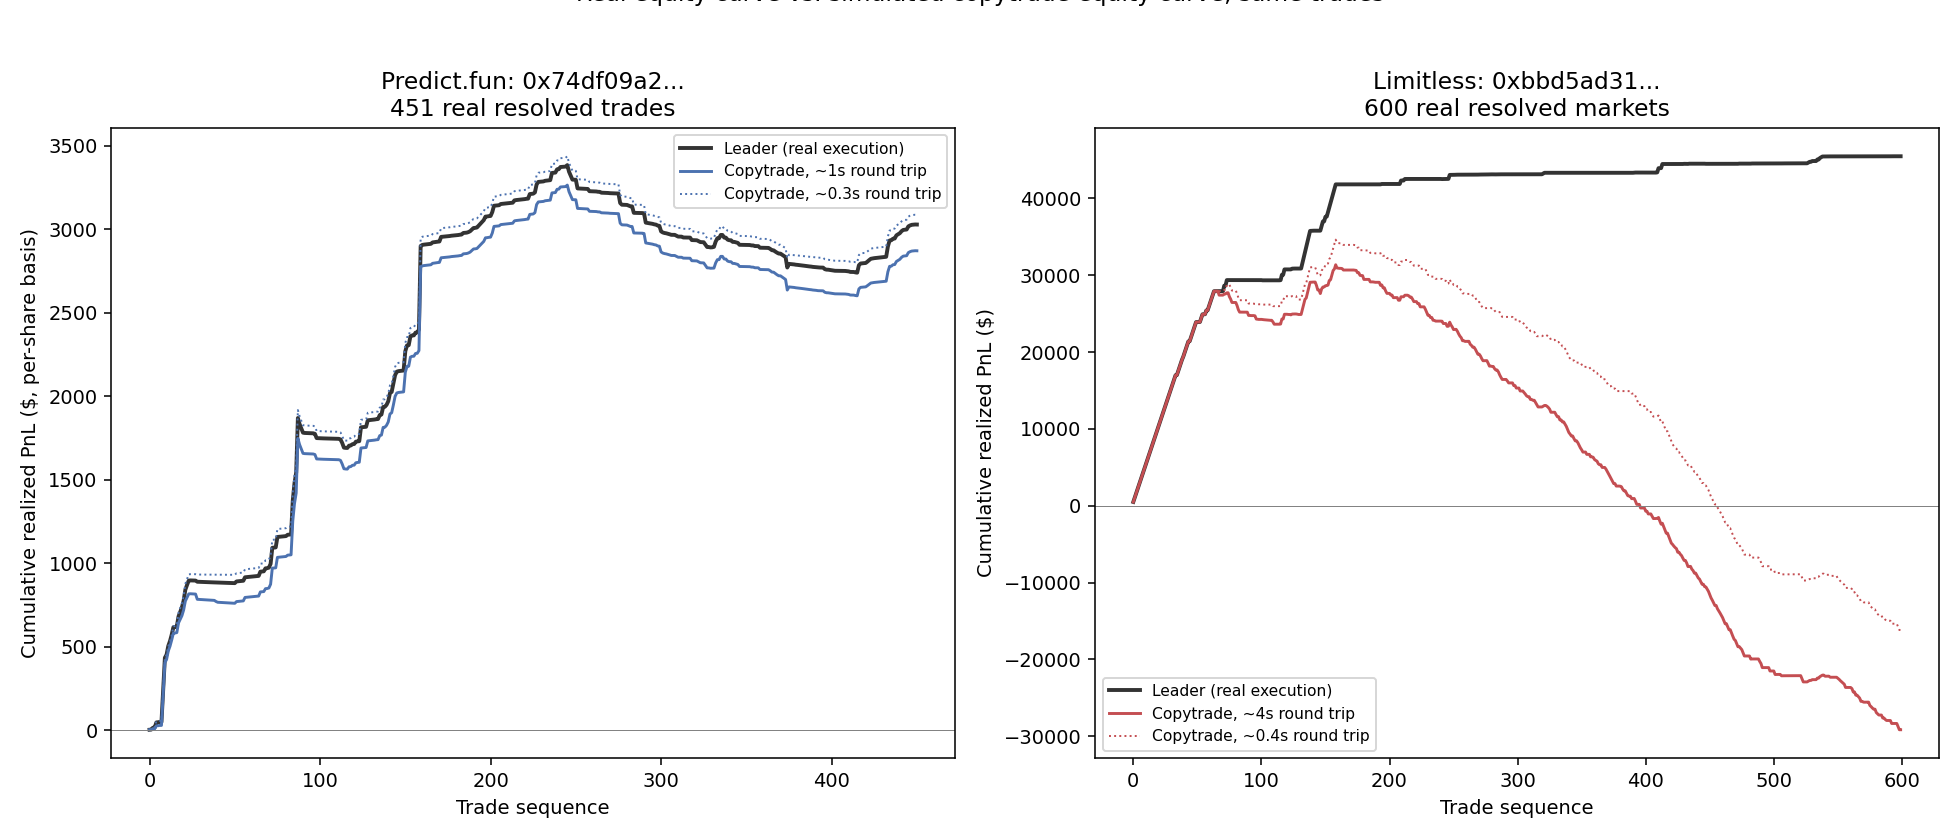

In [ ]:
import matplotlib.pyplot as plt

def cum(events, idx):
    total, out = 0.0, []
    for e in events:
        total += e[idx]
        out.append(total)
    return out

pf_leader, pf_opt, pf_cons = cum(pf_events, 1), cum(pf_events, 2), cum(pf_events, 3)
lim_leader, lim_opt, lim_cons = cum(lim_events, 1), cum(lim_events, 2), cum(lim_events, 3)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].plot(range(len(pf_events)), pf_leader, color="#333333", linewidth=2, label="Leader (real execution)")
axes[0].plot(range(len(pf_events)), pf_cons, color="#4C72B0", linewidth=1.5, label="Copytrade, ~1s round trip")
axes[0].plot(range(len(pf_events)), pf_opt, color="#4C72B0", linewidth=1, linestyle=":", label="Copytrade, ~0.3s round trip")
axes[0].axhline(0, color="gray", linewidth=0.5)
axes[0].set_xlabel("Trade sequence"); axes[0].set_ylabel("Cumulative realized PnL ($)")
axes[0].set_title(f"Predict.fun: 1 account, {len(pf_events)} real resolved trades")
axes[0].legend(fontsize=8)

axes[1].plot(range(len(lim_events)), lim_leader, color="#333333", linewidth=2, label="Leader (real execution)")
axes[1].plot(range(len(lim_events)), lim_cons, color="#C44E52", linewidth=1.5, label="Copytrade, ~4s round trip")
axes[1].plot(range(len(lim_events)), lim_opt, color="#C44E52", linewidth=1, linestyle=":", label="Copytrade, ~0.4s round trip")
axes[1].axhline(0, color="gray", linewidth=0.5)
axes[1].set_xlabel("Trade sequence"); axes[1].set_ylabel("Cumulative realized PnL ($)")
axes[1].set_title(f"Limitless: 1 account, {len(lim_events)} real resolved markets")
axes[1].legend(fontsize=8)

fig.suptitle("Real equity curve vs. simulated copytrade equity curve, same trades", y=1.02)
fig.tight_layout()
plt.show()


In [ ]:
print(f"Predict.fun ({len(pf_events)} trades): leader=${pf_leader[-1]:.2f}  "
      f"optimistic copytrade=${pf_opt[-1]:.2f}  conservative copytrade=${pf_cons[-1]:.2f}")
print(f"Limitless ({len(lim_events)} markets): leader=${lim_leader[-1]:.2f}  "
      f"optimistic copytrade=${lim_opt[-1]:.2f}  conservative copytrade=${lim_cons[-1]:.2f}")


Predict.fun (451 trades): leader=$3029.08  optimistic copytrade=$3087.31  conservative copytrade=$2871.83
Limitless (600 markets): leader=$45491.59  optimistic copytrade=$-16163.43  conservative copytrade=$-29146.48


**Predict.fun's directional strategy survives copytrading comfortably.**
The conservative-delay copytrade curve ($2,872) tracks about 5% below the leader's real
$3,029 — a real cost, not a rounding error, but nowhere near enough to erase the edge. The
optimistic-delay curve ($3,087) is actually slightly *above* the leader's own result.

**Limitless's dual-sided arbitrage does not survive copytrading at all, at either delay.**
The leader's real equity curve closes at **+$45,492** over 600 resolved markets. The
identical trades, with only the taker leg replaced by a realistic copytrade fill, close at
**-$29,146** (conservative round trip) or **-$16,163** (optimistic). Per-market, the median
cost of copytrading is exactly $0 — consistent with the earlier finding that typical
slippage is tiny — but 38% of the 600 markets cost more than $100 each, up to $586 on the
worst one, and that tail alone is larger than the entire strategy's real profit. A strategy
built on a thin, high-volume edge is exactly the kind of strategy where the tail risk
established earlier stops being an abstract percentile and starts being the whole
ballgame.

## Practical implications

- **The strategy type decides whether copytrading survives, more than speed does.** A
  directional strategy (Predict.fun) loses a real but modest ~5% to copytrading at a
  conservative latency. A thin-margin, high-volume arbitrage strategy (Limitless) loses
  everything and goes substantially negative, at *either* a conservative or an optimistic
  latency — because its entire edge is smaller, per trade, than the tail risk a realistic
  copytrading delay exposes it to.
- **At a realistic round-trip latency, median slippage is close to zero on both venues.**
  Predict.fun's optimistic round trip (0.1-0.3s, off-chain match) shows a median
  statistically indistinguishable from — or slightly better than — the leader's own price.
  Limitless's optimistic round trip (0.4s, Flashblocks preconfirmation) shows median
  slippage of under a tenth of a cent. A real edge should survive this comfortably.
- **The tail is the real cost, and it doesn't shrink with speed.** Limitless's 90th
  percentile sits at 0.60+ regardless of whether the round trip is 0.4 seconds or 4 — the
  distribution is bimodal, not continuous, so there's no delay short enough to dodge the
  cluster of trades that hit a genuine liquidity collapse.
- **Detection latency is architecture-dependent, not a single number.** An off-chain-matched
  venue (Predict.fun) lets a well-built bot react in well under a second; an on-chain-matched
  venue (Limitless) has a real floor set by the chain's own block time, roughly 0.4-4
  seconds on Base depending on whether you accept Flashblocks preconfirmation risk. Neither
  number should be assumed — both come from the venue's actual settlement design, confirmed
  here against current, dated figures (BNB Chain's Fermi hard fork, Base's Flashblocks).
- **A naive "time between our own observations" is not a latency measurement.** An earlier
  pass at this analysis made exactly that mistake, reporting a sub-second number that had
  nothing to do with how fast a real copytrading bot could actually act. Any latency claim
  in this kind of analysis needs to be tied to the venue's real matching and settlement
  architecture, not the convenience of whatever data happened to be collected.
- **Check when an account trades relative to each market's own lifecycle before copytrading
  it.** Every tail case in this study came from a trade placed in the back half of a
  window — exactly where the entry-timing histograms above show these profitable accounts
  concentrate their activity.